In [1]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# Sample data parameters
n_rows = 5000

# Categories and their respective items dictionary
categories = {
    'Dairy & Bakery': ['Milk 1L', 'Curd 400g', 'Butter 500g', 'Brown Bread', 'Paneer 200g'],
    'Staples & Grains': [
        'Basmati Rice 5kg',
        'Wheat Flour 10kg',
        'Toor Dal 1kg',
        'Sugar 5kg',
        'Mustard Oil 1L',
    ],
    'Snacks & Beverages': [
        'Potato Chips',
        'Green Tea Bags',
        'Biscuits Pack',
        'Cold Drink 1.5L',
        'Chocolates',
    ],
    'Personal & Household': [
        'Toothpaste 150g',
        'Bath Soap',
        'Washing Powder 1kg',
        'Dishwash Bar',
        'Floor Cleaner 1L',
    ],
}

# Data generation logic for categories and items
cat_list = []
item_list = []
for _ in range(n_rows):
  c = np.random.choice(list(categories.keys()))
  i = np.random.choice(categories[c])
  cat_list.append(c)
  item_list.append(i)

# Generate transaction IDs and dates
transaction_ids = [f'TRX-{j:05d}' for j in range(1, n_rows + 1)]
dates = pd.date_range(start='2025-01-01', end='2025-12-31', periods=n_rows)

# Pricing dictionary for items (Cost Price & Selling Price)
price_mapping = {
    'Milk 1L': (58, 64),
    'Curd 400g': (32, 38),
    'Butter 500g': (240, 265),
    'Brown Bread': (35, 42),
    'Paneer 200g': (80, 95),
    'Basmati Rice 5kg': (450, 520),
    'Wheat Flour 10kg': (340, 390),
    'Toor Dal 1kg': (120, 140),
    'Sugar 5kg': (210, 235),
    'Mustard Oil 1L': (135, 155),
    'Potato Chips': (20, 25),
    'Green Tea Bags': (180, 210),
    'Biscuits Pack': (25, 30),
    'Cold Drink 1.5L': (85, 99),
    'Chocolates': (40, 50),
    'Toothpaste 150g': (95, 115),
    'Bath Soap': (30, 38),
    'Washing Powder 1kg': (110, 130),
    'Dishwash Bar': (15, 20),
    'Floor Cleaner 1L': (160, 190),
}

cost_prices = []
unit_prices = []
for item in item_list:
  cp, sp = price_mapping[item]
  cost_prices.append(cp)
  unit_prices.append(sp)
    
# Weighted quantities and customer IDs
quantities = np.random.choice([1, 2, 3, 4, 5], size=n_rows, p=[0.5, 0.3, 0.1, 0.08, 0.02])
customer_ids = [f'CUST-{np.random.randint(1000, 1200)}' for _ in range(n_rows)]

# Create DataFrame
df = pd.DataFrame({
    'Transaction_ID': transaction_ids,
    'Date': dates,
    'Customer_ID': customer_ids,
    'Category': cat_list,
    'Item_Name': item_list,
    'Quantity': quantities,
    'Unit_Price': unit_prices,
    'Cost_Price': cost_prices,
})

# Convert date column to standard YYYY-MM-DD format without time
df['Date'] = pd.to_datetime(df['Date']).dt.date

# Calculate total revenue, total cost, and total profit columns
df['Total_Revenue'] = df['Quantity'] * df['Unit_Price']
df['Total_Cost'] = df['Quantity'] * df['Cost_Price']
df['Total_Profit'] = df['Total_Revenue'] - df['Total_Cost']

# Save DataFrame to CSV file
df.to_csv('grocery_store_data.csv', index=False)
print(
    'Dataset successfully generated and saved as "grocery_store_data.csv"! Total'
    f' rows: {len(df)}'
)

Dataset successfully generated and saved as "grocery_store_data.csv"! Total rows: 5000


In [2]:
df

,Transaction_ID,Date,Customer_ID,Category,Item_Name,Quantity,Unit_Price,Cost_Price,Total_Revenue,Total_Cost,Total_Profit
0,TRX-00001,2025-01-01,CUST-1156,Snacks & Beverages,Cold Drink 1.5L,2,99,85,198,170,28
1,TRX-00002,2025-01-01,CUST-1109,Dairy & Bakery,Butter 500g,2,265,240,530,480,50
2,TRX-00003,2025-01-01,CUST-1123,Personal & Household,Floor Cleaner 1L,1,190,160,190,160,30
3,TRX-00004,2025-01-01,CUST-1066,Dairy & Bakery,Curd 400g,3,38,32,114,96,18
4,TRX-00005,2025-01-01,CUST-1070,Snacks & Beverages,Biscuits Pack,2,30,25,60,50,10
...,...,...,...,...,...,...,...,...,...,...,...
4995,TRX-04996,2025-12-30,CUST-1192,Dairy & Bakery,Paneer 200g,1,95,80,95,80,15
4996,TRX-04997,2025-12-30,CUST-1184,Snacks & Beverages,Biscuits Pack,1,30,25,30,25,5
4997,TRX-04998,2025-12-30,CUST-1061,Staples & Grains,Mustard Oil 1L,1,155,135,155,135,20
4998,TRX-04999,2025-12-30,CUST-1019,Snacks & Beverages,Potato Chips,2,25,20,50,40,10


In [3]:
df.duplicated().sum()

np.int64(0)

In [4]:
df.dtypes

Transaction_ID       str
Date              object
Customer_ID          str
Category             str
Item_Name            str
Quantity           int64
Unit_Price         int64
Cost_Price         int64
Total_Revenue      int64
Total_Cost         int64
Total_Profit       int64
dtype: object

In [5]:
cat_cols = df.dtypes[df.dtypes=="str"]
cat_cols

Transaction_ID    str
Customer_ID       str
Category          str
Item_Name         str
dtype: object

In [6]:
nv = df.isna().sum()

In [7]:
nv

Transaction_ID    0
Date              0
Customer_ID       0
Category          0
Item_Name         0
Quantity          0
Unit_Price        0
Cost_Price        0
Total_Revenue     0
Total_Cost        0
Total_Profit      0
dtype: int64

In [8]:
df.index

RangeIndex(start=0, stop=5000, step=1)

In [9]:
df.columns

Index(['Transaction_ID', 'Date', 'Customer_ID', 'Category', 'Item_Name',
       'Quantity', 'Unit_Price', 'Cost_Price', 'Total_Revenue', 'Total_Cost',
       'Total_Profit'],
      dtype='str')

In [10]:
import sqlite3
import pandas as pd

# Read the generated CSV file using pandas
df = pd.read_csv('grocery_store_data.csv')

# Create SQLite database connection (this will create a local file named 'grocery_store.db')
conn = sqlite3.connect('grocery_store.db')

# Convert the Pandas DataFrame into a SQL table named 'transactions'
df.to_sql('transactions', conn, if_exists='replace', index=False)

print(
    'Success! Database "grocery_store.db" has been created and data is loaded'
    ' into the "transactions" table.'
)

# Define a helper function to easily execute SQL queries and return results as a DataFrame
def run_query(query):
  return pd.read_sql_query(query, conn)

Success! Database "grocery_store.db" has been created and data is loaded into the "transactions" table.


In [11]:
# 1. Category-wise Business Performance (Revenue & Profit)

In [12]:
query_1 = """
SELECT
    Category,
    COUNT(DISTINCT Transaction_ID) AS Total_Orders,
    SUM(Quantity) AS Total_Units_Sold,
    ROUND(SUM(Total_Revenue), 2) AS Revenue,
    ROUND(SUM(Total_Profit), 2) AS Profit,
    ROUND((100.0 * SUM(Total_Profit) / SUM(Total_Revenue)), 2) AS Profit_Margin_Pct
FROM transactions
GROUP BY Category
ORDER BY Revenue DESC;
"""

print('--- Category-wise Performance ---')
display(run_query(query_1))

--- Category-wise Performance ---


,Category,Total_Orders,Total_Units_Sold,Revenue,Profit,Profit_Margin_Pct
0,Staples & Grains,1250,2246,661065.0,85250.0,12.90
1,Dairy & Bakery,1278,2305,230747.0,27278.0,11.82
2,Personal & Household,1235,2219,216780.0,36515.0,16.84
3,Snacks & Beverages,1237,2195,185121.0,28521.0,15.41


In [13]:
# 2. Top 5 Best-Selling Products

In [14]:
query_2 = """
SELECT 
    Item_Name,
    Category,
    SUM(Quantity) AS Total_Quantity_Sold,
    ROUND(SUM(Total_Revenue), 2) AS Total_Revenue,
    ROUND(AVG(Unit_Price), 2) AS Avg_Selling_Price
FROM transactions
GROUP BY Item_Name, Category
ORDER BY Total_Quantity_Sold DESC
LIMIT 5;
"""

print('--- Best-Selling Products ---')
display(run_query(query_2))

--- Best-Selling Products ---


,Item_Name,Category,Total_Quantity_Sold,Total_Revenue,Avg_Selling_Price
0,Basmati Rice 5kg,Staples & Grains,513,266760.0,520.0
1,Paneer 200g,Dairy & Bakery,508,48260.0,95.0
2,Bath Soap,Personal & Household,490,18620.0,38.0
3,Green Tea Bags,Snacks & Beverages,462,97020.0,210.0
4,Brown Bread,Dairy & Bakery,459,19278.0,42.0


In [15]:
# 3. Monthly Revenue & Growth Trend

In [16]:
query_3 = """
SELECT 
    strftime('%Y-%m', Date) AS Month,
    COUNT(Transaction_ID) AS Total_Transactions,
    ROUND(SUM(Total_Revenue), 2) AS Monthly_Revenue,
    ROUND(SUM(Total_Profit), 2) AS Monthly_Profit
FROM transactions
GROUP BY Month
ORDER BY Month ASC;
"""

print('\n--- Monthly Revenue Trend ---')
display(run_query(query_3))


--- Monthly Revenue Trend ---


,Month,Total_Transactions,Monthly_Revenue,Monthly_Profit
0,2025-01,426,101534.0,14141.0
1,2025-02,385,96592.0,13307.0
2,2025-03,426,113585.0,15342.0
3,2025-04,412,102463.0,14062.0
4,2025-05,425,100020.0,13596.0
5,2025-06,412,99617.0,13745.0
6,2025-07,426,117262.0,16112.0
7,2025-08,426,105330.0,14672.0
8,2025-09,412,110349.0,15192.0
9,2025-10,425,115603.0,15678.0


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Set the overall visual style for clean graphs
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

In [18]:
# 1) Category-wise Revenue Bar Chart 

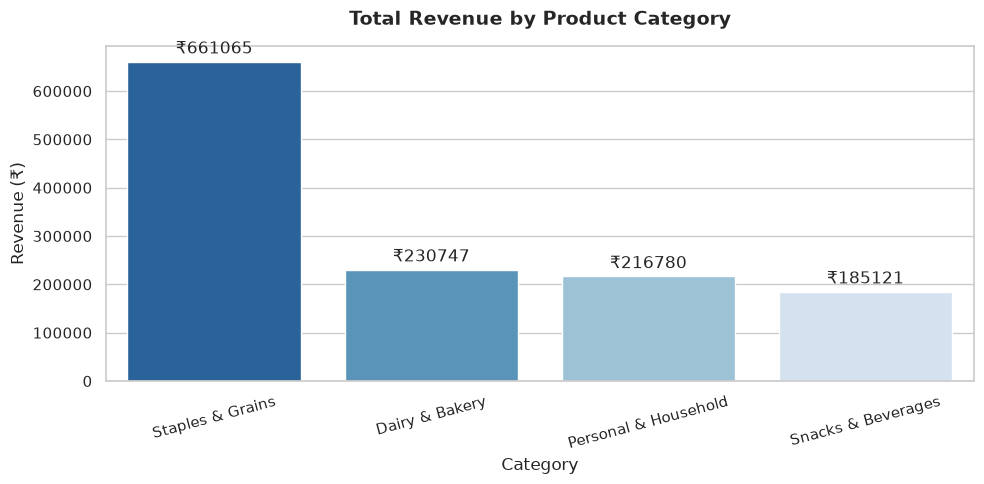

In [19]:
cat_df = run_query("""
    SELECT Category, SUM(Total_Revenue) AS Revenue 
    FROM transactions 
    GROUP BY Category 
    ORDER BY Revenue DESC;
""")

plt.figure(figsize=(10, 5))
ax = sns.barplot(x='Category', y='Revenue', data=cat_df, palette='Blues_r', hue='Category')
# ax.bar_label(ax.containers[0])
# ax.bar_label(ax.containers[1])
# ax.bar_label(ax.containers[2])
# ax.bar_label(ax.containers[3])
for c in ax.containers:
  ax.bar_label(c,fmt='₹%.0f', padding=3)
plt.title('Total Revenue by Product Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Revenue (₹)', fontsize=12)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

**Key Takeaways:**
* **Staples & Grains** brings in by far the highest revenue at ₹6,61,065—almost triple the next category—making it the backbone of store sales.
* **Dairy & Bakery** (₹2,30,747), **Personal & Household** (₹2,16,780), and **Snacks & Beverages** (₹1,85,121) sit in a fairly close range, each contributing roughly ₹1.85L–₹2.31L.
* Keeping staples well-stocked is critical for steady footfall and volume, while bundles or add-on offers across the other three categories can help lift overall basket size.

In [20]:
# 2) Monthly Revenue Trend Line Chart

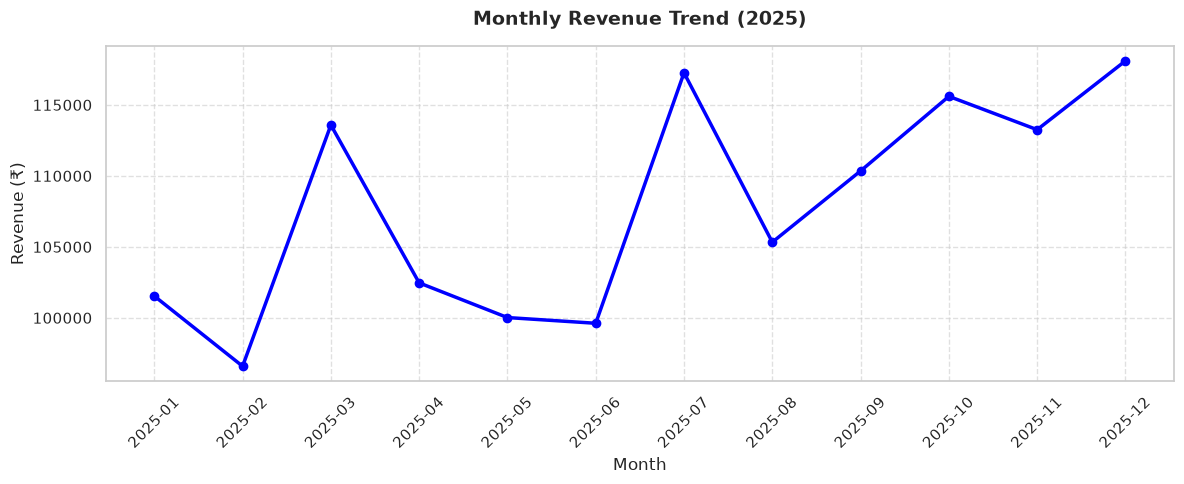

In [21]:
monthly_df = run_query("""
    SELECT strftime('%Y-%m', Date) AS Month, SUM(Total_Revenue) AS Monthly_Revenue
    FROM transactions
    GROUP BY Month
    ORDER BY Month ASC;
""")

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_df['Month'],
    monthly_df['Monthly_Revenue'],
    marker='o',
    color='blue',
    linewidth=2.5,
    markersize=6)
plt.title('Monthly Revenue Trend (2025)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Revenue (₹)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Key Takeaways:**
* Monthly revenue starts around ₹1,01,000 in January 2025, dips to the lowest point of the year in February (just under ₹97,000), and then jumps sharply in March to around ₹1,13,500.
* After cooling down through April–June (hovering near ₹1,00,000–₹1,02,500), sales spike to a major peak in July (around ₹1,17,500) before dropping back in August.
* From August onward, the trend generally climbs again and reaches its highest level in December 2025 (around ₹1,18,000), showing stronger momentum in the second half of the year.

## Step: Customer RFM (Recency, Frequency, Monetary) Analysis
Extracting customer purchase behavior metrics to identify high-value and loyal buyers.

In [22]:
# Establish connection to the SQLite database
conn = sqlite3.connect('grocery_store.db')

# SQL query to calculate RFM (Recency, Frequency, Monetary) metrics per customer
rfm_query = """
    SELECT 
        Customer_ID,
        -- Recency: Days elapsed since the customer's last purchase relative to the max date
        julianday('2025-12-31') - julianday(MAX(Date)) AS Recency,
        -- Frequency: Total number of distinct transactions made by the customer
        COUNT(DISTINCT Transaction_ID) AS Frequency,
        -- Monetary: Total revenue generated from the customer
        ROUND(SUM(Total_Revenue), 2) AS Monetary
    FROM transactions
    GROUP BY Customer_ID
    ORDER BY Monetary DESC;
"""

# Load the result into a Pandas DataFrame
rfm_df = pd.read_sql(rfm_query, conn)

# Display the top 10 high-value customers
rfm_df.head(20)

,Customer_ID,Recency,Frequency,Monetary
0,CUST-1111,5.0,47,11944.0
1,CUST-1014,6.0,38,11865.0
2,CUST-1140,9.0,25,11773.0
3,CUST-1050,31.0,28,11012.0
4,CUST-1141,1.0,26,10266.0
5,CUST-1109,3.0,24,10172.0
6,CUST-1128,4.0,29,10158.0
7,CUST-1088,16.0,28,10125.0
8,CUST-1142,26.0,39,10031.0
9,CUST-1079,5.0,22,10030.0


In [23]:
# Create a copy of the dataframe to avoid modifying the original data
rfm_segmented = rfm_df.copy()

# Assign scores from 1 to 5 for Recency, Frequency, and Monetary
# For Recency: Lower days (more recent) get a higher score (5 is best, 1 is worst)
rfm_segmented['R_Score'] = pd.qcut(rfm_segmented['Recency'], q=5, labels=[5, 4, 3, 2, 1])

# For Frequency: Higher frequency gets a higher score (5 is best, 1 is worst)
# Note: Using rank(method='first') to handle duplicate edges in qcut if any
rfm_segmented['F_Score'] = pd.qcut(rfm_segmented['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])

# For Monetary: Higher monetary value gets a higher score (5 is best, 1 is worst)
rfm_segmented['M_Score'] = pd.qcut(rfm_segmented['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

# Convert score columns to integers
rfm_segmented[['R_Score', 'F_Score', 'M_Score']] = rfm_segmented[['R_Score', 'F_Score', 'M_Score']].astype(int)

# Combine scores into a single RFM Score string
rfm_segmented['RFM_Score'] = (rfm_segmented['R_Score'].astype(str) + rfm_segmented['F_Score'].astype(str) + rfm_segmented['M_Score'].astype(str))


# Define a function to segment customers based on their R and F scores
def segment_customers(df):
  if df['R_Score'] >= 4 and df['F_Score'] >= 4:
    return 'Champions'
  elif df['R_Score'] >= 3 and df['F_Score'] >= 3:
    return 'Loyal Customers'
  elif df['R_Score'] >= 4 and df['F_Score'] == 1:
    return 'Recent Customers'
  elif df['R_Score'] <= 2 and df['F_Score'] >= 3:
    return 'At-Risk Customers'
  elif df['R_Score'] <= 2 and df['F_Score'] <= 2:
    return 'Hibernating'
  else:
    return 'Potential Loyalists'


# Apply the segmentation function
rfm_segmented['Customer_Segment'] = rfm_segmented.apply(segment_customers, axis=1)

# View segment distribution counts
print(rfm_segmented['Customer_Segment'].value_counts())
print('\n--- Sample Data ---')
print(rfm_segmented[['Customer_ID', 'Monetary', 'RFM_Score', 'Customer_Segment']].head(10))

Customer_Segment
Champions              42
Loyal Customers        41
Hibernating            38
At-Risk Customers      37
Potential Loyalists    32
Recent Customers       10
Name: count, dtype: int64

--- Sample Data ---
  Customer_ID  Monetary RFM_Score     Customer_Segment
0   CUST-1111   11944.0       455            Champions
1   CUST-1014   11865.0       455            Champions
2   CUST-1140   11773.0       335      Loyal Customers
3   CUST-1050   11012.0       145    At-Risk Customers
4   CUST-1141   10266.0       535      Loyal Customers
5   CUST-1109   10172.0       535      Loyal Customers
6   CUST-1128   10158.0       545            Champions
7   CUST-1088   10125.0       245    At-Risk Customers
8   CUST-1142   10031.0       155    At-Risk Customers
9   CUST-1079   10030.0       425  Potential Loyalists


#### Plotly Bar Chart: Segment-wise Customer Count & Revenue

In [24]:
import plotly.express as px

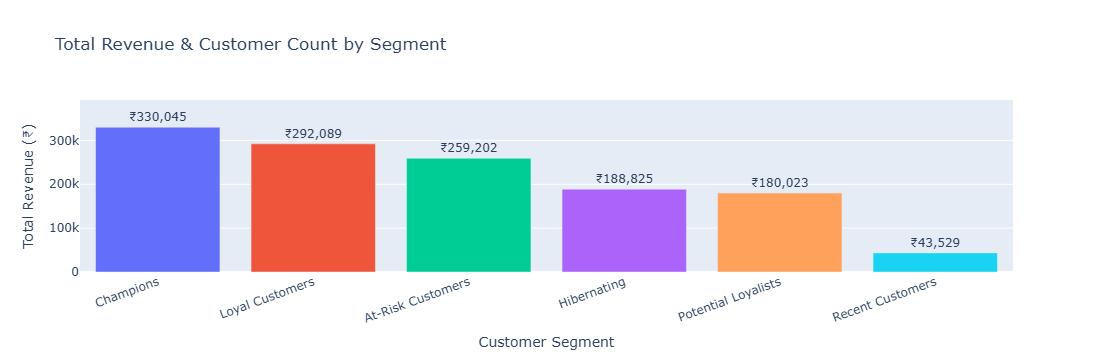

In [25]:
# Prepare segment summary data
seg_summary = (
    rfm_segmented.groupby('Customer_Segment', as_index=False)
    .agg(
        Customer_Count=('Customer_ID', 'count'),
        Total_Revenue=('Monetary', 'sum'),
        Avg_Monetary=('Monetary', 'mean'),
    )
    .sort_values(by='Total_Revenue', ascending=False)
)

fig_bar = px.bar(seg_summary,x='Customer_Segment',y='Total_Revenue',color='Customer_Segment',text_auto='.2s',
    hover_data={'Customer_Count': True,'Avg_Monetary': ':,.0f','Total_Revenue': ':,.0f'},
    title='Total Revenue & Customer Count by Segment',
    labels={'Customer_Segment': 'Customer Segment','Total_Revenue': 'Total Revenue (₹)'},)

fig_bar.update_traces(texttemplate='₹%{y:,.0f}', textposition='outside')
fig_bar.update_layout(showlegend=False, xaxis_tickangle=-20)
fig_bar.show()

**Key Takeaways:**
* **Champions** (₹3,30,045) and **Loyal Customers** (₹2,92,089) bring in the most money, showing how important regular, high-spending buyers are to the store.
* **At-Risk Customers** (₹2,59,202) are still a big revenue source, so reaching out to them soon can stop us from losing that business.
* **Recent Customers** (₹43,529) are at the bottom right now, which makes sense since they are newer—getting them to make a second purchase is a great next step.

#### Plotly Box Plot: Monetary Distribution & Outliers

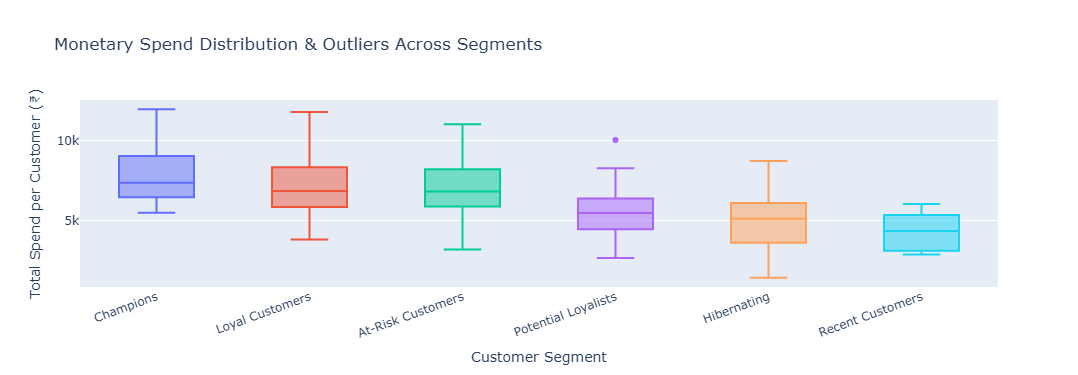

In [26]:
fig_box = px.box(rfm_segmented, x='Customer_Segment', y='Monetary', color='Customer_Segment',
    points='outliers',  # Shows outlier dots outside the whiskers
    hover_data=['Customer_ID', 'Recency', 'Frequency', 'RFM_Score'],
    title='Monetary Spend Distribution & Outliers Across Segments',
    labels={'Customer_Segment': 'Customer Segment', 'Monetary': 'Total Spend per Customer (₹)'})

fig_box.update_layout(showlegend=False, xaxis_tickangle=-20)
fig_box.show()

**Key Takeaways:**
* **Champions** have the highest spend overall, with a median around ₹7.3k and values stretching up to nearly ₹12k.
* **Loyal Customers** and **At-Risk Customers** follow closely, with medians right around ₹7k and wide ranges from roughly ₹3k–₹4k up to ₹11k–₹12k.
* **Potential Loyalists**, **Hibernating**, and **Recent Customers** spend noticeably less per person, with medians around ₹4k–₹5.5k and **Recent Customers** topping out near ₹6k.
* **Potential Loyalists** has one clear high-spend outlier dot around ₹10k above its upper whisker, while **Hibernating** reaches down to the lowest spend point on the chart (just under ₹2k).

#### Trending Plotly Chart: Segment Revenue & Recency Treemap

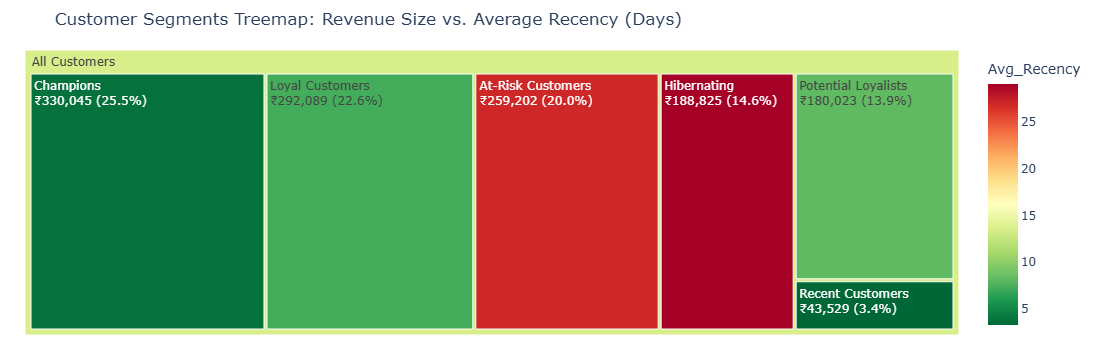

In [27]:
import plotly.express as px

# Prepare segment summary for Treemap
treemap_df = (rfm_segmented.groupby('Customer_Segment', as_index=False).agg(
        Customers=('Customer_ID', 'count'),
        Total_Revenue=('Monetary', 'sum'),
        Avg_Monetary=('Monetary', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Recency=('Recency', 'mean'),
    ).round(1))

fig_treemap = px.treemap(treemap_df,path=[px.Constant('All Customers'), 'Customer_Segment'],values='Total_Revenue',color='Avg_Recency',
    color_continuous_scale='RdYlGn_r',  # Lower recency (fresher) = greener, higher = reddish
    hover_data={'Customers': True,'Total_Revenue': ':,.0f','Avg_Monetary': ':,.0f','Avg_Frequency': True,'Avg_Recency': True},
    title='Customer Segments Treemap: Revenue Size vs. Average Recency (Days)')

fig_treemap.update_traces(
    textinfo='label+value+percent parent',
    texttemplate='%{label}<br>₹%{value:,.0f} (%{percentParent:.1%})')
fig_treemap.update_layout(margin=dict(t=50, l=25, r=25, b=25))
fig_treemap.show()

**Key Takeaways:**
* **At-Risk Customers** (₹2,59,202 | 20.0%) and **Hibernating** (₹1,88,825 | 14.6%) show up in dark red because it has been a while since their last order—good targets for reminder messages or small discounts.
* **Champions** (₹3,30,045 | 25.5%) and **Recent Customers** (₹43,529 | 2.6%) are in green, meaning their purchases are much fresher.
* Looking at both size and recency together helps prioritize: keep **Champions** happy, nudge **Potential Loyalists** (₹1,80,023 | 13.9%) to come back sooner, and try to win back older buyers who haven't visited in a while.